# Prices, returns and empirical distributions

This analysis compares price patterns, simple and log returns, and the shape of observed return
distributions across equities, energy and exchange rates. Histograms, sample moments
and Q–Q plots provide complementary comparisons with a Normal benchmark.

The analysis uses daily observations for **2010–2025**: US market and industry portfolio returns,
energy spot prices, and exchange rates.

Data Sources:

- Equity market and value-weighted industry portfolios: [Ken French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html);
- EIA observations: FRED [Brent](https://fred.stlouisfed.org/series/DCOILBRENTEU) and [Henry Hub gas](https://fred.stlouisfed.org/series/DHHNGSP);
- FED Exchange rates: FRED [EUR](https://fred.stlouisfed.org/series/DEXUSEU),
[JPY](https://fred.stlouisfed.org/series/DEXJPUS) and
[GBP](https://fred.stlouisfed.org/series/DEXUSUK).

## Libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

## Data


In [2]:
# Load daily observations and use dates as the index.
data = pd.read_csv(
    "daily_market_data.csv",
    index_col="date",
    parse_dates=True
)

# Keep the sample period used throughout the analysis.
data = data.loc["2010-01-01":"2025-12-31"]
display(data.head())

,Mkt-RF,RF,BusEq,Enrgy,Hlth,DCOILBRENTEU,DHHNGSP,DEXUSEU,DEXJPUS,DEXUSUK
date,,,,,,,,,,
2010-01-04,0.0169,0.0,0.0159,0.0300,0.0131,79.05,6.09,1.4419,92.55,1.6109
2010-01-05,0.0031,0.0,0.0000,0.0078,-0.0060,79.27,6.19,1.4402,91.48,1.6009
2010-01-06,0.0013,0.0,-0.0069,0.0094,0.0053,80.14,6.47,1.4404,92.53,1.6016
2010-01-07,0.0040,0.0,-0.0036,-0.0033,0.0013,80.57,7.51,1.4314,93.31,1.5912
2010-01-08,0.0033,0.0,0.0076,0.0045,0.0025,80.06,6.56,1.4357,92.70,1.5993


In [3]:
# Equity returns are already expressed in decimals (0.01 = 1%).
# Mkt-RF is the excess market return: add RF to recover the total return.
# Industry portfolios already contain total returns, including dividends.
# Drop dates with no equity observations; retain missing values in individual series.
equity_returns = pd.DataFrame({
    "US market": data["Mkt-RF"] + data["RF"],
    "Technology stocks": data["BusEq"],
    "Energy stocks": data["Enrgy"],
    "Healthcare stocks": data["Hlth"],
}).dropna(how="all")

# Energy columns contain spot prices, rather than returns.
# EUR and GBP are quoted in USD per unit of foreign currency.
# Invert JPY per USD so all three exchange rates use the same convention.
# A rise in an exchange rate then indicates appreciation against the dollar.
spot_levels = pd.DataFrame({
    "Brent spot": data["DCOILBRENTEU"],
    "Natural gas spot": data["DHHNGSP"],
    "EUR in USD": data["DEXUSEU"],
    "JPY in USD": 1 / data["DEXJPUS"],
    "GBP in USD": data["DEXUSUK"],
})

# Define the series order and axis labels for the plots below.
names = list(equity_returns) + list(spot_levels)
units = {
    **{name: "Cumulative return (%)" for name in equity_returns},
    "Brent spot": "USD/barrel",
    "Natural gas spot": "USD/million BTU",
    "EUR in USD": "USD/EUR",
    "JPY in USD": "USD/JPY",
    "GBP in USD": "USD/GBP",
}

## Total and excess returns

The **total return** measures an investment's gain or loss over a period, including dividends.
The **excess return** measures how much this return exceeds the risk-free return
over the same period:

$$
R_t^e = R_t - R_t^f.
$$

For example, a daily total return of 1.00% and a daily risk-free return of 0.02%
give an excess return of 0.98%. A negative excess return means the investment
underperformed the risk-free asset; its total return can still be positive.

In the supplied Ken French data, `Mkt-RF` is the excess return on the US market
and `RF` is the risk-free return. The data preparation above recovers the total market return:

$$
R_t^m = R_t^{m,e} + R_t^f = \text{Mkt-RF}_t + \text{RF}_t.
$$

The analysis below uses total equity returns to calculate cumulative returns and compare
return distributions. The industry portfolio columns already provide total returns.


## Levels and a common scale

Supplied equity returns generate the cumulative return:
$$C_t = \prod_{s=1}^{t}(1+R_s)-1.$$
The individual equity plots show $100C_t$, the cumulative return in percent.
It starts at 0% on 31 December 2009, immediately before the sample begins.

For the group comparisons on a common base of 100, the same returns generate an index:
$$W_t = 100\prod_{s=1}^{t}(1+R_s).$$
An index value of 150 corresponds to a cumulative return of 50%.
An observed positive spot level can instead be rebased as $I_t=100P_t/P_0$.
Each spot series uses its first available observation as its base.

Rebasing changes units without changing percentage movements. Equity total returns include
distributions; energy spot prices and FX quotations exclude carry and the costs of holding a position.


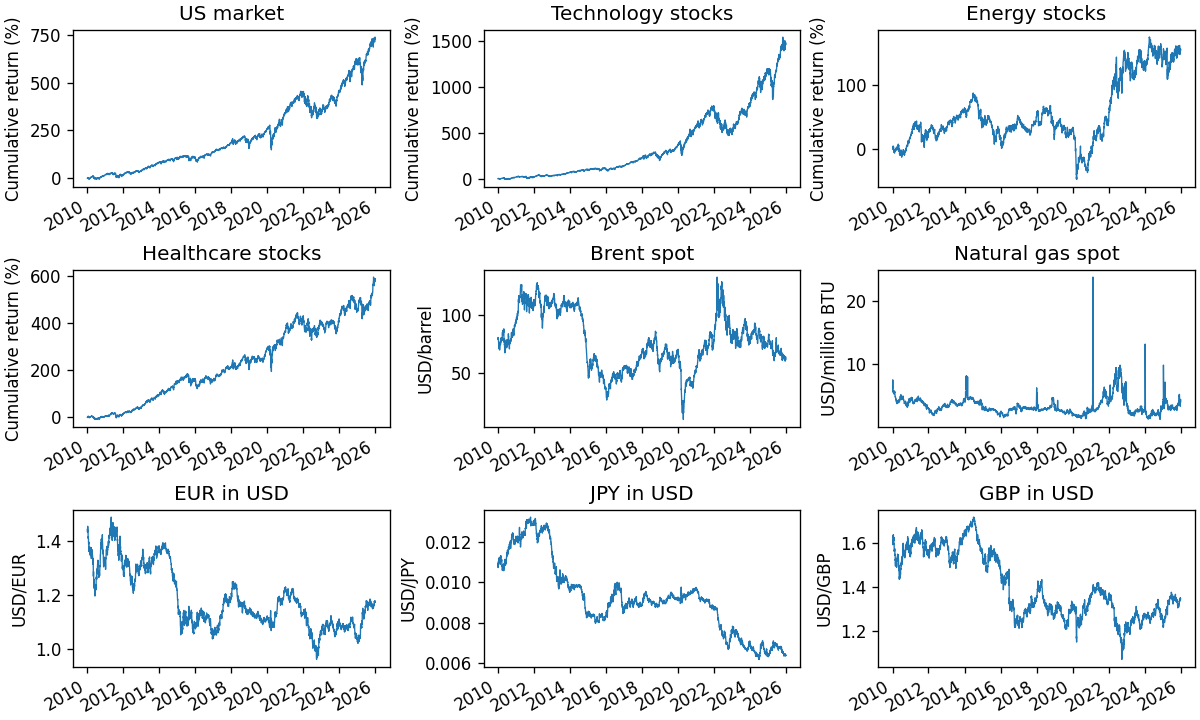

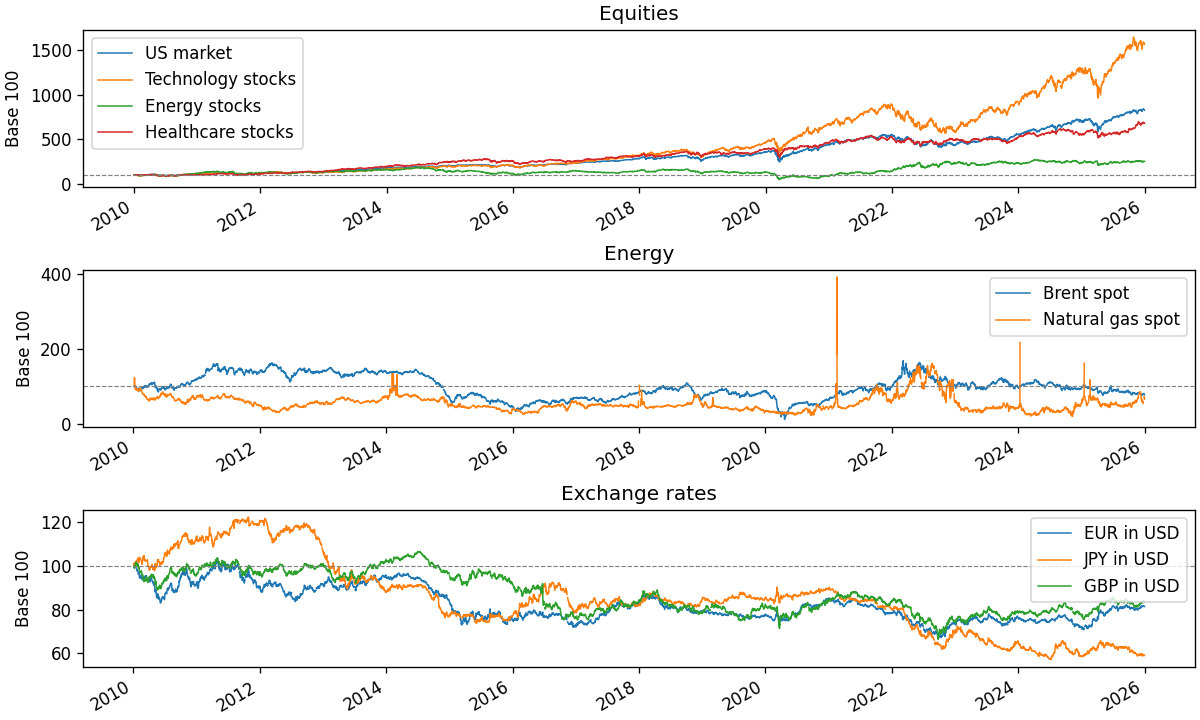

In [4]:
equity_index = 100 * (1 + equity_returns).cumprod()
anchor = pd.DataFrame(100.0, index=[pd.Timestamp("2009-12-31")], columns=equity_returns.columns)
equity_index = pd.concat([anchor, equity_index])
# Convert the base-100 equity index to cumulative returns in percent.
equity_cumulative_returns = equity_index - 100
spot_rebased = pd.DataFrame({
    name: 100 * spot_levels[name] / spot_levels[name].dropna().iloc[0]
    for name in spot_levels
})
normalized = pd.concat([equity_index, spot_rebased], axis=1, sort=True)

fig, axes = plt.subplots(3, 3, figsize=(10, 6), constrained_layout=True)
for ax, name in zip(axes.flat, names):
    level = equity_cumulative_returns[name] if name in equity_returns else spot_levels[name]
    level.dropna().plot(ax=ax, lw=0.8)
    ax.set(title=name, ylabel=units[name], xlabel="")
plt.show()

groups = {
    "Equities": list(equity_returns),
    "Energy": ["Brent spot", "Natural gas spot"],
    "Exchange rates": ["EUR in USD", "JPY in USD", "GBP in USD"],
}
fig, axes = plt.subplots(3, 1, figsize=(10, 6), constrained_layout=True)
for ax, (group, columns) in zip(axes, groups.items()):
    normalized[columns].plot(ax=ax, lw=0.9)
    ax.axhline(100, color="gray", ls="--", lw=0.7)
    ax.set(title=group, ylabel="Base 100", xlabel="")
plt.show()


## Simple and log returns

For a positive level $P_t$, the simple return is the change relative to the preceding level:

$$
R_t=\frac{P_t-P_{t-1}}{P_{t-1}}=\frac{P_t}{P_{t-1}}-1.
$$

The log return is the difference between their logarithms:

$$
r_t=\log P_t-\log P_{t-1}=\log\left(\frac{P_t}{P_{t-1}}\right)=\log(1+R_t).
$$

A decimal return of 0.01 means 1%. For small changes, $r_t\approx R_t$.
Simple returns compound through products; log returns add over successive intervals.
Price logarithms require $P_t>0$, and the log of a simple gross return requires $R_t>-1$.


In [5]:
spot_returns = {}
spot_log_returns = {}

for name in spot_levels:
    # Remove missing levels within each spot or FX series before calculating changes.
    prices = spot_levels[name].dropna()

    # Align the preceding available observation, which may be more than one calendar day earlier.
    # For a Monday this can be Friday; missing-data gaps can span longer intervals.
    # The first observation has no preceding price, so its return remains missing.
    previous_prices = prices.shift(1)

    # Simple return: (current price - previous price) / previous price.
    spot_returns[name] = (prices - previous_prices) / previous_prices

    # Log return: log(current price) - log(previous price).
    spot_log_returns[name] = np.log(prices) - np.log(previous_prices)

spot_returns = pd.DataFrame(spot_returns).sort_index()
spot_log_returns = pd.DataFrame(spot_log_returns).sort_index()

# Ken French equity values already are simple returns; convert them to log returns.
equity_log_returns = np.log(1 + equity_returns)

# Join the return series by date, retaining the different source calendars.
returns = pd.concat([equity_returns, spot_returns], axis=1, sort=True).sort_index()
log_returns = pd.concat([equity_log_returns, spot_log_returns], axis=1, sort=True).sort_index()
display((100 * returns.head()).round(3))


,US market,Technology stocks,Energy stocks,Healthcare stocks,Brent spot,Natural gas spot,EUR in USD,JPY in USD,GBP in USD
date,,,,,,,,,
2010-01-04,1.69,1.59,3.00,1.31,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.31,0.00,0.78,-0.60,0.278,1.642,-0.118,1.170,-0.621
2010-01-06,0.13,-0.69,0.94,0.53,1.098,4.523,0.014,-1.135,0.044
2010-01-07,0.40,-0.36,-0.33,0.13,0.537,16.074,-0.625,-0.836,-0.649
2010-01-08,0.33,0.76,0.45,0.25,-0.633,-12.650,0.300,0.658,0.509


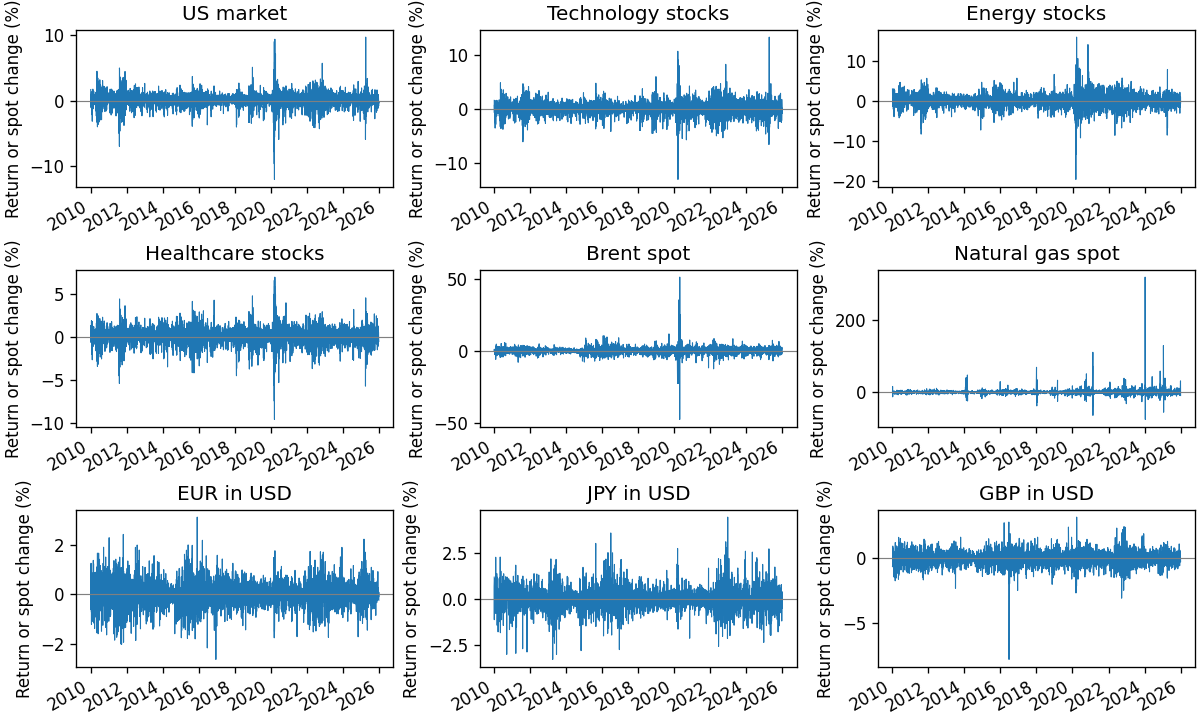

US market              0.783337
Technology stocks      0.942724
Energy stocks          2.235153
Healthcare stocks      0.494718
Brent spot            16.904453
Natural gas spot     175.766181
EUR in USD             0.047432
JPY in USD             0.094775
GBP in USD             0.324790
Name: Largest |log − simple| (percentage points), dtype: float64

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(10, 6), constrained_layout=True)
for ax, name in zip(axes.flat, names):
    (100 * returns[name].dropna()).plot(ax=ax, lw=0.65)
    ax.axhline(0, color="gray", lw=0.7)
    ax.set(title=name, ylabel="Return or spot change (%)", xlabel="")
plt.show()

display((100 * (log_returns - returns).abs().max()).rename("Largest |log − simple| (percentage points)"))

The strong movements visible in levels become positive and negative fluctuations when expressed
as returns. Large movements can cluster in time (**volatiliy clusters**), and their scale can change across the sample.
A mean near zero does not imply small losses or constant dispersion. The difference between
simple and log returns becomes more visible for large changes.


## Distribution shape and the Normal benchmark

Standardizing each column separates shape from the scale of its volatility:
$$z_t=\frac{R_t-\bar R}{s},$$
where $s$ is the sample standard deviation. The reference curve is a standard Normal density.
A histogram shows the marginal distribution and discards the time ordering of observations.


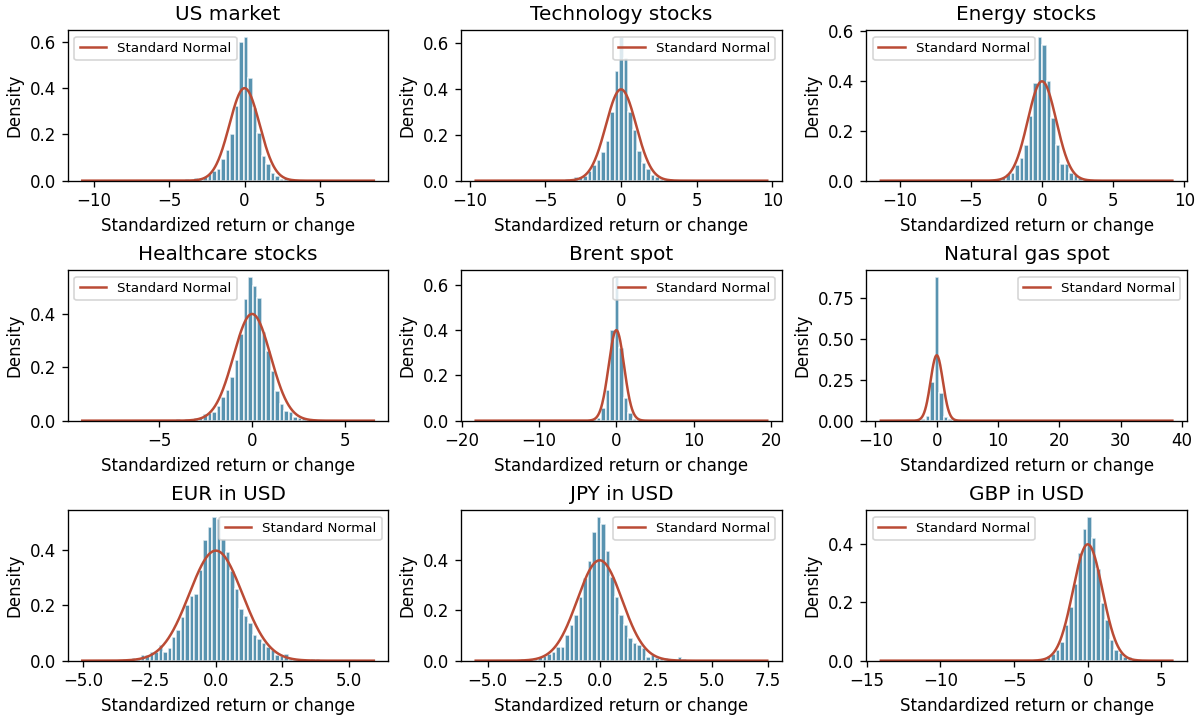

In [7]:
standardized = (returns - returns.mean()) / returns.std(ddof=1)
fig, axes = plt.subplots(3, 3, figsize=(10, 6), constrained_layout=True)
for ax, name in zip(axes.flat, names):
    z = standardized[name].dropna()
    ax.hist(z, bins=65, density=True, color="#2e789c", edgecolor="white", alpha=0.8)
    x = np.linspace(min(-4, z.min()), max(4, z.max()), 600)
    ax.plot(x, stats.norm.pdf(x), color="#ba4b35", label="Standard Normal")
    ax.set(title=name, xlabel="Standardized return or change", ylabel="Density")
    ax.legend(fontsize=8)
plt.show()

### Sample moments and extreme frequencies

Skewness measures asymmetry. Excess kurtosis measures the contribution of extreme
deviations from the mean: it is the standardized fourth moment minus three.
The Normal reference is zero. Positive excess kurtosis is often associated with
heavier (fat) tails, meaning a greater weight of extreme observations relative to the
distribution's variance. It does not directly measure the probability of an extreme event.

The frequency of observations more than three sample standard deviations from the mean
complements these moments. Under a standard Normal distribution,
the corresponding probability is approximately 0.27%.


In [8]:
rows = []
for name in names:
    x = returns[name].dropna()
    z = standardized[name].dropna()
    rows.append({
        "series": name,
        "n": len(x),
        "mean (%)": 100 * x.mean(),
        "sd (%)": 100 * x.std(ddof=1),
        "skewness": stats.skew(x, bias=False),
        "excess kurtosis": stats.kurtosis(x, fisher=True, bias=False),
        "|z| > 3 (%)": 100 * (z.abs() > 3).mean(),
        "Normal |z| > 3 (%)": 100 * 2 * stats.norm.sf(3),
    })
summary = pd.DataFrame(rows).set_index("series")
display(summary.round(4))


,n,mean (%),sd (%),skewness,excess kurtosis,|z| > 3 (%),Normal |z| > 3 (%)
series,,,,,,,
US market,4024,0.0588,1.1219,-0.4077,11.7004,1.4911,0.27
Technology stocks,4024,0.0778,1.3745,-0.1161,8.3396,1.3419,0.27
Energy stocks,4024,0.0386,1.7427,-0.3221,11.1884,1.2922,0.27
Healthcare stocks,4024,0.0533,1.0586,-0.3288,5.8056,1.2674,0.27
Brent spot,4046,0.0284,2.6124,0.7430,78.6106,0.8898,0.27
Natural gas spot,4020,0.2415,8.2963,16.1652,574.9170,0.9204,0.27
EUR in USD,4000,-0.0038,0.5243,0.0396,1.7899,1.1250,0.27
JPY in USD,4000,-0.0114,0.5918,0.2123,4.1698,1.5750,0.27
GBP in USD,4000,-0.0030,0.5584,-0.6910,11.6543,0.8250,0.27


In this sample, all nine series have positive excess kurtosis. The departures from the Normal
reference differ substantially across markets; natural gas contains particularly large proportional
changes. A low preceding price can amplify a percentage change, so an extreme return should be
interpreted alongside its underlying levels.


### Normal Q–Q plots

Each sorted standardized observation is compared with its corresponding theoretical Normal
quantile. Agreement with the identity line supports the Normal approximation at those quantiles;
deviations in the tails reveal where the approximation misses extreme observations.


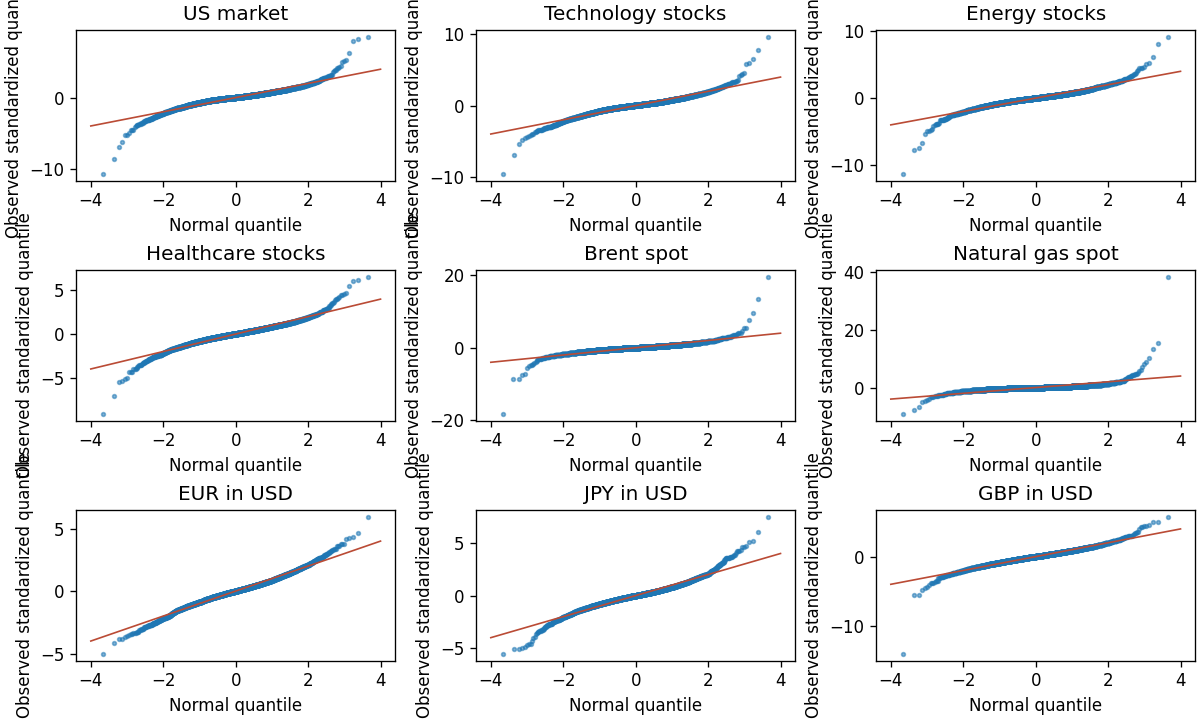

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(10, 6), constrained_layout=True)
for ax, name in zip(axes.flat, names):
    z = np.sort(standardized[name].dropna().to_numpy())
    probabilities = (np.arange(1, len(z) + 1) - 0.5) / len(z)
    theoretical = stats.norm.ppf(probabilities)
    ax.scatter(theoretical, z, s=5, alpha=0.55)
    ax.plot([-4, 4], [-4, 4], color="#ba4b35", lw=1)
    ax.set(title=name, xlabel="Normal quantile", ylabel="Observed standardized quantile")
plt.show()


Symmetry and tail thickness describe different features: a nearly symmetric distribution can
still contain many extreme observations. Histograms, moments, extreme frequencies and Q–Q plots
are therefore read together. Sample moments are sensitive to extreme events and the chosen period;
their values alone do not identify a particular population distribution.
